# 05 – Results

Tables and figures for the report, computed from the files written by `01_data_preparation.ipynb`,
`02_train_models.ipynb`, `03_control_experiments.ipynb` and `04_reduced_labels.ipynb`. Nothing is trained here.
All numbers are on the 600 test images. A model's value is the mean over its seeds.

## 1. Setup

In [1]:
import json
import textwrap
from itertools import combinations
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from scipy.stats import ttest_ind

from aidml import (CHECKPOINT_DIR, RESULTS_DIR, build_model, compute_metrics, get_device, load_data, load_runs,
                   make_batch, scene_object_table, split_indices)

FIGURE_DIR = Path("figures")
FIGURE_DIR.mkdir(exist_ok=True)
MODELS = ["B0", "B1", "B2"]
CONTROLS = ["B1_noextra", "B1_shuffled", "B0_long"]
REDUCED = ["B0_labels25", "B0_long_labels25", "B1_labels25", "B2_labels25"]
ALL_RUNS = MODELS + CONTROLS + REDUCED
COLORS = {"B0": "#2a78d6", "B1": "#eb6834", "B2": "#1baf7a"}

data = load_data()
test = split_indices(data, "test")
truth = data["objects"][test].astype(bool)
object_names = data["object_names"]
scene_specific = json.load(open(RESULTS_DIR / "scene_specific_labels.json"))
reference = json.load(open(RESULTS_DIR / "reference_predictors.json"))
runs = {m: load_runs(m) for m in ALL_RUNS}
probs = {m: [np.load(RESULTS_DIR / f"{m}_seed{run['seed']}_test_object_probs.npy") for run in runs[m]]
         for m in ALL_RUNS}
for m in ALL_RUNS:
    print(f"{m:12s} seeds: {[run['seed'] for run in runs[m]]}")

B0           seeds: [0, 1, 2]
B1           seeds: [0, 1, 2]
B2           seeds: [0, 1, 2]
B1_noextra   seeds: [0, 1, 2]
B1_shuffled  seeds: [0, 1, 2]
B0_long      seeds: [0, 1, 2]
B0_labels25  seeds: [0, 1, 2]
B0_long_labels25 seeds: [0, 1, 2]
B1_labels25  seeds: [0, 1, 2]
B2_labels25  seeds: [0, 1, 2]


## 2. Data checks

Matching between the multi-label release and the original AID, and the size of each split.
Validation and test images are never used for training: the scene head is trained on the 2,160 multi-label
training images and the 7,000 scene-only images.

In [2]:
print(json.dumps(json.load(open(RESULTS_DIR / "matching.json")), indent=2))
print(pd.Series(data["split"]).value_counts().to_string())

{
  "multilabel_images": 3000,
  "distinct_matches": 3000,
  "largest_match_distance": 0.09110862016677856,
  "smallest_second_best_distance": 0.386422723531723,
  "closest_other_image_to_a_test_image": 0.43018436431884766,
  "mean_pixel_difference": 1.01565682888031,
  "largest_pixel_difference": 2.174412727355957,
  "images_per_scene": [
    100,
    100
  ]
}
extra    7000
train    2160
test      600
val       240


## 3. Model size

All models share the ResNet-50 backbone. The scene head adds 30 × 2,049 parameters and the scene prior adds
16 weights, so differences between B0, B1 and B2 cannot come from model capacity. The control runs use the B0 or
B1 architecture.

In [3]:
sizes = {}
for m in MODELS:
    model = build_model(m, data, pretrained=False)
    sizes[m] = sum(p.numel() for p in model.parameters())
pd.DataFrame({"parameters": sizes, "relative to B0": {m: f"{sizes[m] / sizes['B0'] - 1:+.3%}" for m in MODELS}})

,parameters,relative to B0
B0,23540816,+0.000%
B1,23602286,+0.261%
B2,23602302,+0.261%


## 4. Main table

Mean ± standard deviation over seeds (in %). *Label frequency* gives every image the training frequency of each
label and needs no training; it is the chance level for mAP. Hua et al. report an example-based F1 of 86.23 for
a ResNet-50 baseline on their own 80/20 split with 17 labels, so their number is not directly comparable.

In [4]:
METRICS = ["mAP", "example_F1", "example_F2", "macro_F1", "scene_accuracy"]

rows = {"label frequency": {k: f"{100 * reference['label frequency'][k]:.2f}" for k in METRICS[:4]}}
for m in MODELS + CONTROLS:
    if not runs[m]:
        continue
    values = pd.DataFrame([run["test_metrics"] for run in runs[m]])
    rows[m] = {k: f"{100 * values[k].mean():.2f} ± {100 * values[k].std(ddof=0):.2f}"
               for k in METRICS if k in values}
main_table = pd.DataFrame(rows).T.reindex(columns=METRICS).fillna("–")
main_table.to_csv(RESULTS_DIR / "main_table.csv")
main_table

,mAP,example_F1,example_F2,macro_F1,scene_accuracy
label frequency,32.28,69.99,69.54,26.76,–
B0,89.68 ± 0.45,91.02 ± 0.37,91.00 ± 0.41,84.19 ± 0.71,–
B1,90.63 ± 0.04,91.43 ± 0.36,91.56 ± 0.46,84.89 ± 0.34,97.17 ± 0.36
B2,90.89 ± 0.33,91.63 ± 0.16,91.80 ± 0.21,85.61 ± 0.42,97.44 ± 0.16
B1_noextra,90.34 ± 0.20,91.23 ± 0.21,91.16 ± 0.31,84.47 ± 0.44,95.83 ± 0.24
B1_shuffled,88.03 ± 0.66,89.95 ± 0.55,89.81 ± 0.73,82.02 ± 0.56,3.28 ± 1.76
B0_long,89.62 ± 0.08,90.66 ± 0.32,90.72 ± 0.19,84.38 ± 0.31,–


## 5. Are the differences real?

Two sources of noise are checked for every pair of models:

- **Seeds** (randomness of training): Welch's t-test on the per-seed mAP, and an exact one-sided permutation
  test (with 3 seeds per model, the smallest possible p-value is 1/20 = 0.05).
- **Test images** (the choice of the 600 test images): paired bootstrap. The test images are resampled with
  replacement 1,000 times; for each resample the mAP difference is computed on the same images for both models
  (averaged over seeds). We report the 95% interval of the difference and how often it is positive.

The control pairs answer the question of the instructor:

- B1_noextra − B0: scene supervision with exactly the images of B0;
- B1 − B1_noextra: effect of the 7,000 scene-only images;
- B1 − B1_shuffled: effect of the real scene information, with the same images and the same capacity;
- B0_long − B0 and B1 − B0_long: effect of training as long as B1 without scene supervision.

The last three pairs belong to the reduced-label pilot (section 13).

In [5]:
def fast_map(p, t):
    """mAP for continuous scores, used inside the bootstrap (labels without positives are skipped)."""
    order = np.argsort(-p, axis=0)
    t = np.take_along_axis(t, order, axis=0)
    precision = np.cumsum(t, axis=0) / np.arange(1, len(t) + 1)[:, None]
    positives = t.sum(0)
    return ((precision * t).sum(0)[positives > 0] / positives[positives > 0]).mean()


def permutation_p(a, b):
    """One-sided exact permutation test for mean(a) > mean(b)."""
    pooled = np.concatenate([a, b])
    observed = a.mean() - b.mean()
    diffs = [pooled[list(i)].mean() - np.delete(pooled, list(i)).mean() for i in combinations(range(len(pooled)), len(a))]
    return np.mean(np.array(diffs) >= observed - 1e-12)


rng = np.random.default_rng(0)
samples = [rng.integers(0, len(test), len(test)) for _ in range(1000)]
t = truth.astype(float)

pairs = [("B1", "B0"), ("B2", "B0"), ("B2", "B1"), ("B1_noextra", "B0"), ("B1", "B1_noextra"), ("B1", "B1_shuffled"),
         ("B0_long", "B0"), ("B1", "B0_long"),
         ("B1_labels25", "B0_labels25"), ("B1_labels25", "B0_long_labels25"), ("B2_labels25", "B1_labels25")]
rows, boots = [], {}
for a, b in pairs:
    if not runs[a] or not runs[b]:
        continue
    map_a = np.array([run["test_metrics"]["mAP"] for run in runs[a]])
    map_b = np.array([run["test_metrics"]["mAP"] for run in runs[b]])
    boot = np.array([np.mean([fast_map(p[s], t[s]) for p in probs[a]]) - np.mean([fast_map(p[s], t[s]) for p in probs[b]])
                     for s in samples])
    boots[f"{a} - {b}"] = boot
    rows.append({
        "comparison": f"{a} - {b}",
        "mAP difference": round(100 * (map_a.mean() - map_b.mean()), 2),
        "Welch p": round(ttest_ind(map_a, map_b, equal_var=False).pvalue, 3),
        "permutation p": round(permutation_p(map_a, map_b), 3),
        "bootstrap 95% interval": f"[{100 * np.percentile(boot, 2.5):+.2f}, {100 * np.percentile(boot, 97.5):+.2f}]",
        "bootstrap P(difference > 0)": round((boot > 0).mean(), 3),
    })
significance = pd.DataFrame(rows).set_index("comparison")
significance.to_csv(RESULTS_DIR / "significance.csv")
significance

,mAP difference,Welch p,permutation p,bootstrap 95% interval,bootstrap P(difference > 0)
comparison,,,,,
B1 - B0,0.95,0.095,0.05,"[+0.19, +1.77]",0.994
B2 - B0,1.21,0.042,0.05,"[+0.44, +1.99]",1.000
B2 - B1,0.26,0.370,0.20,"[-0.08, +0.66]",0.934
B1_noextra - B0,0.66,0.160,0.10,"[-0.04, +1.41]",0.966
B1 - B1_noextra,0.28,0.171,0.05,"[-0.35, +0.93]",0.812
B1 - B1_shuffled,2.59,0.031,0.05,"[+1.69, +3.52]",1.000
B0_long - B0,-0.06,0.867,0.60,"[-0.46, +0.34]",0.388
B1 - B0_long,1.01,0.001,0.05,"[+0.20, +1.83]",0.996
B1_labels25 - B0_labels25,2.62,0.006,0.05,"[+1.60, +3.73]",1.000


Bootstrap distributions of the mAP differences. The dashed line is zero.

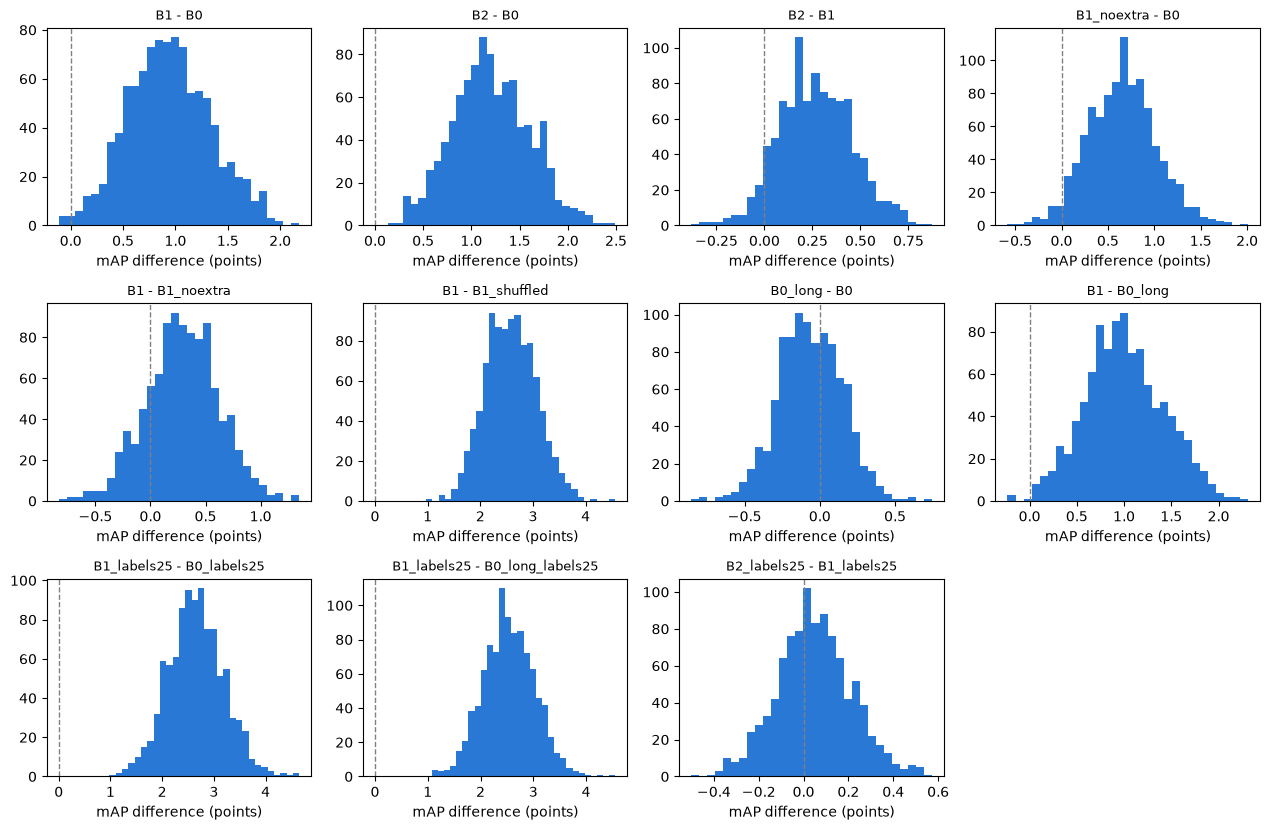

In [6]:
columns = 4
rows = int(np.ceil(len(boots) / columns))
fig, axes = plt.subplots(rows, columns, figsize=(3.2 * columns, 2.8 * rows), squeeze=False)
for ax in axes.ravel()[len(boots):]:
    ax.axis("off")
for ax, (name, boot) in zip(axes.ravel(), boots.items()):
    ax.hist(100 * boot, bins=30, color="#2a78d6")
    ax.axvline(0, color="gray", linestyle="--", linewidth=1)
    ax.set_title(name, fontsize=9)
    ax.set_xlabel("mAP difference (points)")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "bootstrap_differences.png", dpi=200)
plt.show()

## 6. Average precision per label

Bars show the mean over seeds, error bars the standard deviation. Labels marked with * are scene-specific.

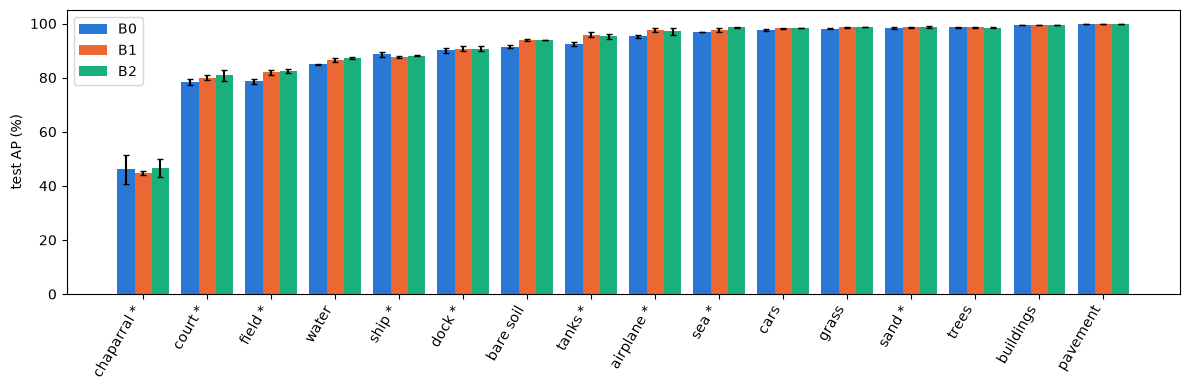

In [7]:
per_label = {m: np.array([run["test_metrics"]["per_label_AP"] for run in runs[m]]) for m in ALL_RUNS if runs[m]}
order = np.argsort(per_label["B0"].mean(0))
x = np.arange(len(object_names))
width = 0.27

plt.figure(figsize=(12, 4))
for k, m in enumerate(MODELS):
    plt.bar(x + (k - 1) * width, 100 * per_label[m].mean(0)[order], width,
            yerr=100 * per_label[m].std(0)[order], color=COLORS[m], label=m, capsize=2)
labels = [object_names[j] + (" *" if object_names[j] in scene_specific else "") for j in order]
plt.xticks(x, labels, rotation=60, ha="right")
plt.ylabel("test AP (%)")
plt.ylim(0, 105)
plt.legend()
plt.tight_layout()
plt.savefig(FIGURE_DIR / "per_label_ap.png", dpi=200)
plt.show()

### 6.1 Rare labels

Labels with fewer than 250 training images, with their number of training and test images.

In [8]:
train_counts = data["objects"][split_indices(data, "train")].sum(0).astype(int)
test_counts = truth.sum(0)
rare = [j for j in np.argsort(train_counts) if train_counts[j] < 250]
rare_table = pd.DataFrame({"train images": train_counts[rare], "test images": test_counts[rare]},
                          index=[object_names[j] for j in rare])
for m in MODELS + CONTROLS:
    if m not in per_label:
        continue
    rare_table[m] = [f"{100 * per_label[m][:, j].mean():.1f} ± {100 * per_label[m][:, j].std():.1f}" for j in rare]
rare_table.to_csv(RESULTS_DIR / "rare_labels.csv")
rare_table

,train images,test images,B0,B1,B2,B1_noextra,B1_shuffled,B0_long
airplane,71,20,95.3 ± 0.6,97.5 ± 0.7,97.1 ± 1.2,95.9 ± 0.3,91.1 ± 1.8,94.9 ± 1.0
tanks,77,22,92.5 ± 0.8,95.8 ± 0.9,95.3 ± 1.0,93.6 ± 0.9,92.3 ± 0.4,92.2 ± 0.6
chaparral,81,24,46.0 ± 5.2,44.8 ± 0.9,46.6 ± 3.3,46.2 ± 1.6,39.0 ± 4.3,47.8 ± 1.3
field,149,47,78.6 ± 0.8,81.9 ± 1.0,82.3 ± 0.7,82.1 ± 1.3,77.6 ± 2.2,79.7 ± 1.4
sea,159,45,96.9 ± 0.1,97.7 ± 0.8,98.6 ± 0.1,97.1 ± 0.5,95.9 ± 0.7,97.1 ± 0.4
sand,186,50,98.3 ± 0.4,98.6 ± 0.3,98.7 ± 0.2,98.6 ± 0.2,96.9 ± 0.6,98.1 ± 0.1
dock,198,53,90.1 ± 1.0,90.7 ± 0.9,90.7 ± 1.0,90.6 ± 1.1,89.8 ± 2.5,88.4 ± 0.4
ship,209,53,88.6 ± 0.9,87.7 ± 0.4,88.1 ± 0.2,88.6 ± 0.9,83.4 ± 2.7,88.0 ± 1.5
court,241,72,78.5 ± 1.0,80.0 ± 1.1,80.9 ± 2.0,78.9 ± 1.1,75.7 ± 1.5,77.6 ± 1.1


### 6.2 Scene-specific vs. other labels

Mean AP gain over B0.

In [9]:
is_specific = np.array([name in scene_specific for name in object_names])
gains = {}
for m in MODELS + CONTROLS:
    if m == "B0" or m not in per_label:
        continue
    gain = 100 * (per_label[m].mean(0) - per_label["B0"].mean(0))
    gains[m] = {"scene-specific labels": gain[is_specific].mean(), "other labels": gain[~is_specific].mean()}
pd.DataFrame(gains).round(2)

,B1,B2,B1_noextra,B1_shuffled,B0_long
scene-specific labels,1.11,1.49,0.76,-2.56,-0.10
other labels,0.74,0.85,0.54,-0.47,-0.01


## 7. Validation mAP during training

Mean over seeds; the shaded band is ± one standard deviation.

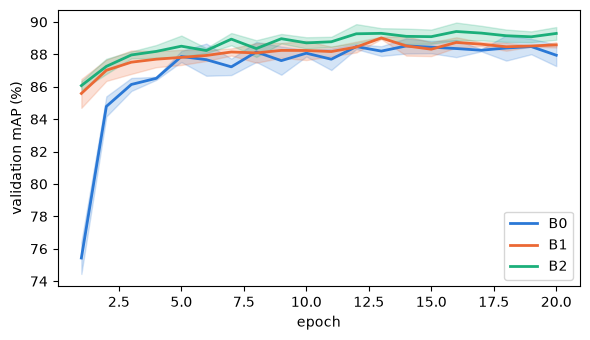

In [10]:
plt.figure(figsize=(6, 3.5))
for m in MODELS:
    curves = np.array([[h["val_mAP"] for h in run["history"]] for run in runs[m]])
    epochs = np.arange(1, curves.shape[1] + 1)
    plt.plot(epochs, 100 * curves.mean(0), color=COLORS[m], linewidth=2, label=m)
    plt.fill_between(epochs, 100 * (curves.mean(0) - curves.std(0)), 100 * (curves.mean(0) + curves.std(0)),
                     color=COLORS[m], alpha=0.2)
plt.xlabel("epoch")
plt.ylabel("validation mAP (%)")
plt.legend()
plt.tight_layout()
plt.savefig(FIGURE_DIR / "validation_curves.png", dpi=200)
plt.show()

Training object loss. A lower final training loss with the same validation mAP means stronger overfitting.

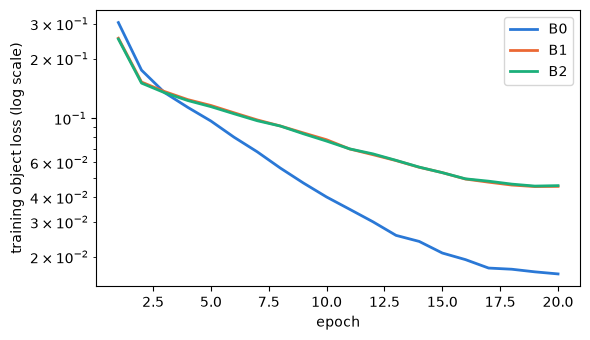

In [11]:
plt.figure(figsize=(6, 3.5))
for m in MODELS:
    curves = np.array([[h["object_loss"] for h in run["history"]] for run in runs[m]])
    plt.plot(np.arange(1, curves.shape[1] + 1), curves.mean(0), color=COLORS[m], linewidth=2, label=m)
plt.yscale("log")
plt.xlabel("epoch")
plt.ylabel("training object loss (log scale)")
plt.legend()
plt.tight_layout()
plt.savefig(FIGURE_DIR / "training_loss.png", dpi=200)
plt.show()

## 8. Scene classifier

Test accuracy of the scene head per scene (B1, mean over seeds). The scene head only sees training and
scene-only images. For B1_shuffled the scene labels are random, so its accuracy should be near chance (1/30).

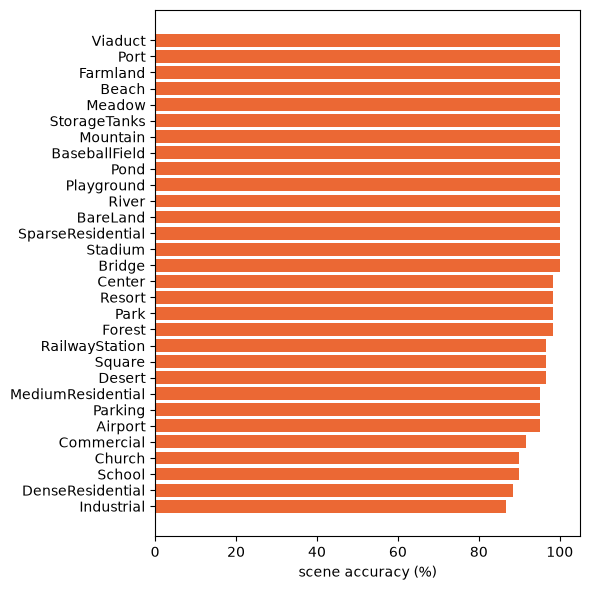

In [12]:
true_scene = data["scenes"][test]
accuracy = []
for run in runs["B1"]:
    scene_probs = np.load(RESULTS_DIR / f"B1_seed{run['seed']}_test_scene_probs.npy")
    accuracy.append(pd.Series(scene_probs.argmax(1) == true_scene).groupby(true_scene).mean())
per_scene = pd.concat(accuracy, axis=1).mean(axis=1)
per_scene.index = [data["scene_names"][s] for s in per_scene.index]
per_scene = per_scene.sort_values()

plt.figure(figsize=(6, 6))
plt.barh(per_scene.index, 100 * per_scene.values, color="#eb6834")
plt.xlabel("scene accuracy (%)")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "scene_accuracy.png", dpi=200)
plt.show()

Confusion matrix of the scene head (B1, seed 0). Only the off-diagonal cells are interesting: they show which
scenes are mixed up, and therefore which images get a wrong scene for B2.

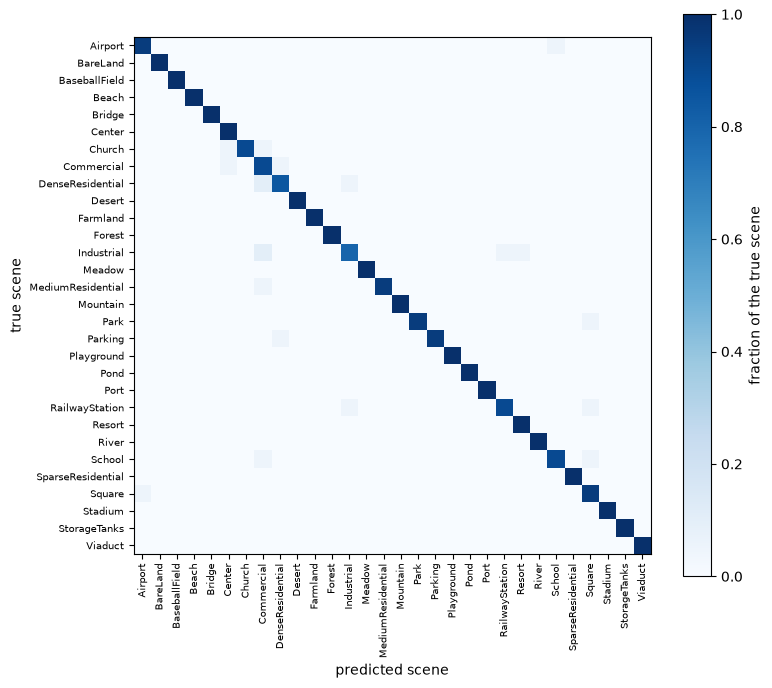

In [13]:
scene_probs = np.load(RESULTS_DIR / f"B1_seed{runs['B1'][0]['seed']}_test_scene_probs.npy")
num_scenes = len(data["scene_names"])
confusion = np.zeros((num_scenes, num_scenes))
for true, pred in zip(true_scene, scene_probs.argmax(1)):
    confusion[true, pred] += 1

plt.figure(figsize=(8, 7))
plt.imshow(confusion / confusion.sum(1, keepdims=True), cmap="Blues", vmin=0, vmax=1)
plt.colorbar(label="fraction of the true scene")
plt.xticks(range(num_scenes), data["scene_names"], rotation=90, fontsize=7)
plt.yticks(range(num_scenes), data["scene_names"], fontsize=7)
plt.xlabel("predicted scene")
plt.ylabel("true scene")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "scene_confusion.png", dpi=200)
plt.show()

## 9. Learned prior weights of B2

B2 adds `w_o · logit(P(o | predicted scene))` to the logit of object *o*. A large weight means the model relies
on the scene for that object; a weight near zero means it ignores the scene.

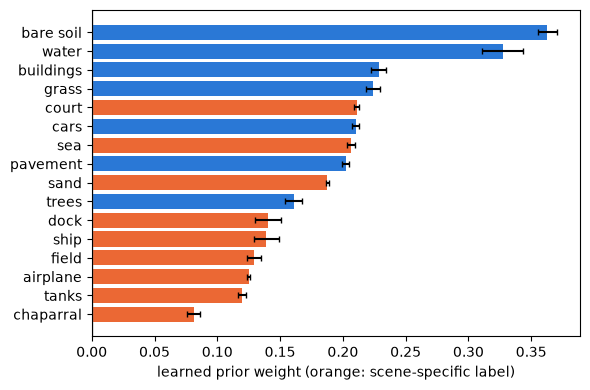

In [14]:
weights = np.array([run["test_metrics"]["prior_weight"] for run in runs["B2"]])
order = np.argsort(weights.mean(0))

plt.figure(figsize=(6, 4))
colors = ["#eb6834" if object_names[j] in scene_specific else "#2a78d6" for j in order]
plt.barh([object_names[j] for j in order], weights.mean(0)[order], xerr=weights.std(0)[order],
         color=colors, capsize=2)
plt.axvline(0, color="gray", linewidth=1)
plt.xlabel("learned prior weight (orange: scene-specific label)")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "prior_weights.png", dpi=200)
plt.show()

## 10. Shortcut errors

A shortcut error is predicting an object because it is typical for the scene although it is not in the image.
We look at all test (image, object) pairs where the object is **absent** and split them by P(object | true scene)
from the training images:

- *typical*: P > 0.5, the object is usually present in this scene;
- *untypical*: P ≤ 0.5.

The true scene is used here only to group the test pairs; the models never see it.

In [15]:
table = scene_object_table(data, smoothing=0)
typical = table[data["scenes"][test]] > 0.5
absent = ~truth
print("absent pairs:", absent.sum(), "| typical:", (absent & typical).sum(), "| untypical:", (absent & ~typical).sum())

rows = {}
for m in MODELS + CONTROLS:
    if not runs[m]:
        continue
    rates = 100 * np.array([[(p >= 0.5)[absent & typical].mean(), (p >= 0.5)[absent & ~typical].mean()] for p in probs[m]])
    rows[m] = {"FPR typical (%)": f"{rates[:, 0].mean():.2f} ± {rates[:, 0].std():.2f}",
               "FPR untypical (%)": f"{rates[:, 1].mean():.2f} ± {rates[:, 1].std():.2f}"}
pd.DataFrame(rows).T

absent pairs: 6501 | typical: 216 | untypical: 6285


,FPR typical (%),FPR untypical (%)
B0,47.38 ± 2.68,2.06 ± 0.05
B1,49.07 ± 2.65,2.11 ± 0.10
B2,48.77 ± 2.52,2.04 ± 0.12
B1_noextra,49.69 ± 4.86,1.85 ± 0.20
B1_shuffled,49.69 ± 1.57,2.19 ± 0.15
B0_long,45.68 ± 3.21,2.31 ± 0.17


## 11. Example predictions

Test images where B2 is better than B0 (top row) and worse than B0 (bottom row), first seed, measured by the
example-based F1 of the image. Under each image: the true labels and, for each model, its wrong predictions
(false positives) and missed labels.

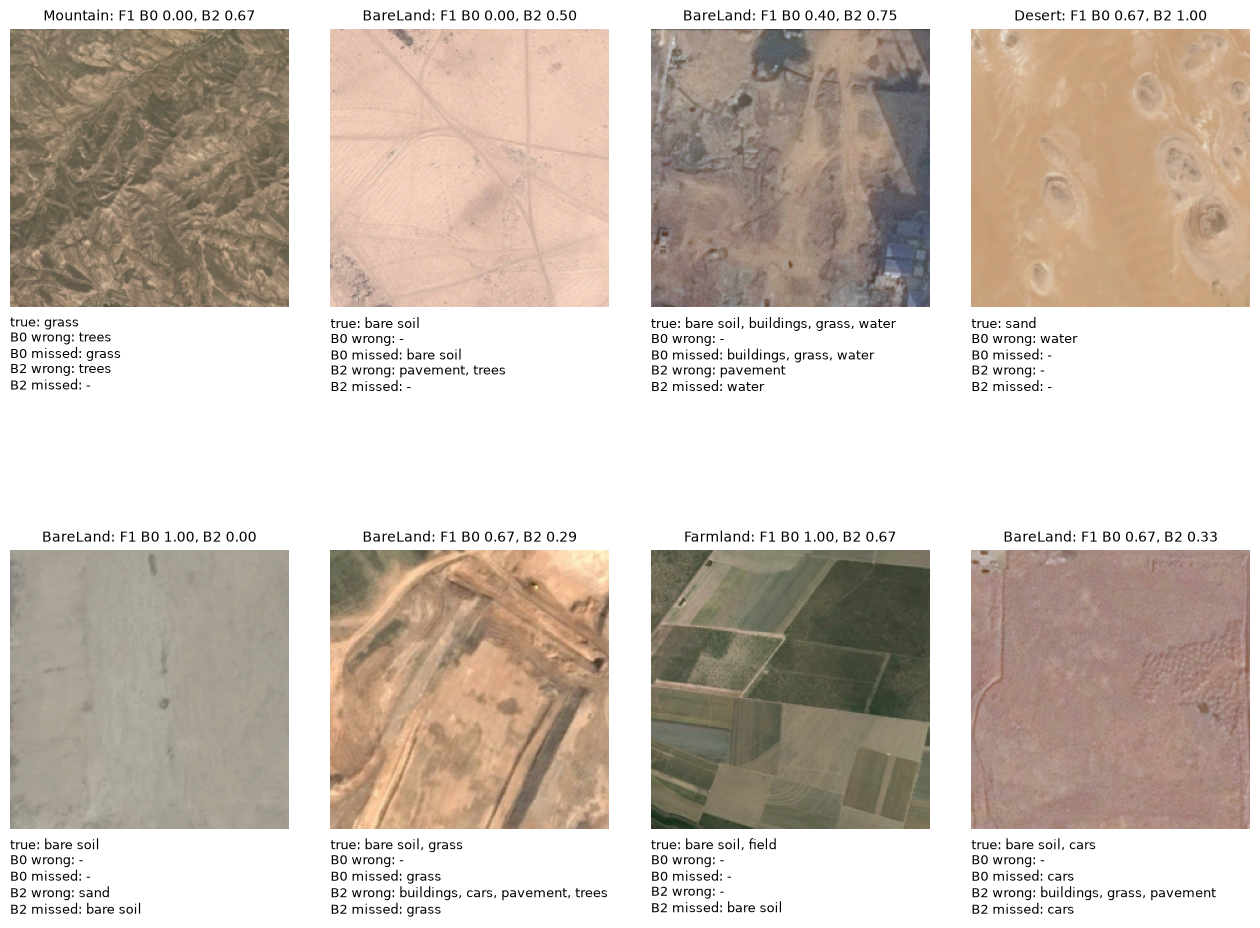

In [16]:
example_probs = {m: probs[m][0] for m in ["B0", "B2"]}


def image_f1(prob, target):
    predicted = prob >= 0.5
    correct = (predicted & target).sum(1)
    return 2 * correct / np.maximum(predicted.sum(1) + target.sum(1), 1)


f1 = {m: image_f1(example_probs[m], truth) for m in ["B0", "B2"]}
change = f1["B2"] - f1["B0"]
chosen = list(np.argsort(change)[-4:][::-1]) + list(np.argsort(change)[:4])


def names(mask):
    return ", ".join(name for name, value in zip(object_names, mask) if value) or "-"


fig, axes = plt.subplots(2, 4, figsize=(16, 11))
for ax, i in zip(axes.ravel(), chosen):
    ax.imshow(data["images"][test[i]])
    ax.set_title(f"{data['scene_names'][data['scenes'][test[i]]]}: F1 B0 {f1['B0'][i]:.2f}, B2 {f1['B2'][i]:.2f}",
                 fontsize=10)
    ax.axis("off")
    lines = [f"true: {names(truth[i])}"]
    for m in ["B0", "B2"]:
        predicted = example_probs[m][i] >= 0.5
        lines.append(f"{m} wrong: {names(predicted & ~truth[i])}")
        lines.append(f"{m} missed: {names(~predicted & truth[i])}")
    text = "\n".join(textwrap.fill(line, 45) for line in lines)
    ax.text(0, -0.03, text, fontsize=9, va="top", transform=ax.transAxes)
plt.subplots_adjust(hspace=0.6, wspace=0.15)
plt.savefig(FIGURE_DIR / "example_predictions.png", dpi=200, bbox_inches="tight")
plt.show()


## 12. Analysis only: how much does the true scene tell?

This predictor gives every test image P(object | its **true** scene) from the training images. It uses the test
scene labels, so it is **not** a model and is not compared with the models above. It only measures how much
information the scene label carries about the objects.

In [17]:
pd.DataFrame(reference).T[["mAP", "example_F1", "macro_F1"]].astype(float).mul(100).round(2)

,mAP,example_F1,macro_F1
label frequency,32.28,69.99,26.76
true-scene prior,86.79,90.36,80.62


## 13. Reduced labels (pilot)

Only 25% of the multi-label training images keep their object labels (see `04_reduced_labels.ipynb`). The table
puts the same models side by side with all labels and with 25% of the labels (mean ± standard deviation over
seeds, in %).

In [18]:
rows = {}
for fraction, suffix in [("100%", ""), ("25%", "_labels25")]:
    for m in ["B0", "B0_long", "B1", "B2"]:
        if not runs.get(m + suffix):
            continue
        values = pd.DataFrame([run["test_metrics"] for run in runs[m + suffix]])
        rows[(fraction, m)] = {k: f"{100 * values[k].mean():.2f} ± {100 * values[k].std(ddof=0):.2f}"
                               for k in ["mAP", "example_F1", "macro_F1"]}
reduced_table = pd.DataFrame(rows).T
reduced_table.to_csv(RESULTS_DIR / "reduced_labels_table.csv")
reduced_table

mAP    example_F1      macro_F1
100% B0       89.68 ± 0.45  91.02 ± 0.37  84.19 ± 0.71
     B0_long  89.62 ± 0.08  90.66 ± 0.32  84.38 ± 0.31
     B1       90.63 ± 0.04  91.43 ± 0.36  84.89 ± 0.34
     B2       90.89 ± 0.33  91.63 ± 0.16  85.61 ± 0.42
25%  B0       85.55 ± 0.38  88.95 ± 0.33  79.65 ± 0.32
     B0_long  85.65 ± 0.62  89.12 ± 0.29  80.02 ± 0.79
     B1       88.17 ± 0.12  90.04 ± 0.17  82.34 ± 0.28
     B2       88.22 ± 0.13  89.88 ± 0.31  82.69 ± 0.24

Mean mAP differences (in points) with all labels and with 25% of the labels. If scene supervision matters more
when labels are scarce, the differences grow in the 25% column. Section 5 has the significance tests.

In [19]:
def mean_map(name):
    return 100 * np.mean([run["test_metrics"]["mAP"] for run in runs[name]]) if runs.get(name) else np.nan


differences = {}
for fraction, suffix in [("100%", ""), ("25%", "_labels25")]:
    differences[fraction] = {f"{a} - {b}": mean_map(a + suffix) - mean_map(b + suffix)
                             for a, b in [("B1", "B0"), ("B1", "B0_long"), ("B2", "B0"), ("B2", "B1"), ("B0_long", "B0")]}
pd.DataFrame(differences).round(2)

,100%,25%
B1 - B0,0.95,2.62
B1 - B0_long,1.01,2.52
B2 - B0,1.21,2.67
B2 - B1,0.26,0.05
B0_long - B0,-0.06,0.10


mAP of every model with all labels and with 25% of the labels. Error bars are the standard deviation over seeds.

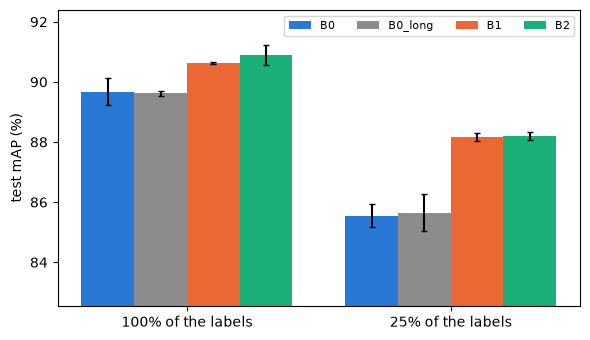

In [20]:
bar_models = ["B0", "B0_long", "B1", "B2"]
bar_colors = {**COLORS, "B0_long": "#8c8c8c"}
width = 0.2
plt.figure(figsize=(6, 3.5))
for k, m in enumerate(bar_models):
    for g, suffix in enumerate(["", "_labels25"]):
        if not runs.get(m + suffix):
            continue
        values = 100 * np.array([run["test_metrics"]["mAP"] for run in runs[m + suffix]])
        plt.bar(g + (k - 1.5) * width, values.mean(), width, yerr=values.std(), color=bar_colors[m], capsize=2,
                label=m if g == 0 else None)
plt.xticks([0, 1], ["100% of the labels", "25% of the labels"])
plt.ylabel("test mAP (%)")
values = [mean_map(m + s) for m in bar_models for s in ["", "_labels25"]]
plt.ylim(np.nanmin(values) - 3, np.nanmax(values) + 1.5)
plt.legend(ncol=4, fontsize=8, loc="upper right")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "reduced_labels_map.png", dpi=200)
plt.show()

AP gain over B0 per group of labels with 25% of the labels, and the learned prior weights of B2 with all labels
and with 25% of the labels. A larger weight means B2 relies more on the scene prior.

In [21]:
if runs["B0_labels25"]:
    base = np.array([run["test_metrics"]["per_label_AP"] for run in runs["B0_labels25"]]).mean(0)
    gains = {}
    for m in ["B0_long_labels25", "B1_labels25", "B2_labels25"]:
        if runs[m]:
            gain = 100 * (np.array([run["test_metrics"]["per_label_AP"] for run in runs[m]]).mean(0) - base)
            gains[m] = {"scene-specific labels": gain[is_specific].mean(), "other labels": gain[~is_specific].mean()}
    display(pd.DataFrame(gains).round(2))

prior_weights = {}
for name in ["B2", "B2_labels25"]:
    if runs[name]:
        prior_weights[name] = np.array([run["test_metrics"]["prior_weight"] for run in runs[name]]).mean(0)
pd.DataFrame(prior_weights, index=object_names).round(3)

,B0_long_labels25,B1_labels25,B2_labels25
scene-specific labels,0.27,3.87,3.92
other labels,-0.11,1.02,1.06


,B2,B2_labels25
airplane,0.125,0.058
bare soil,0.363,0.197
buildings,0.229,0.089
cars,0.210,0.085
chaparral,0.081,0.031
court,0.211,0.100
dock,0.140,0.063
field,0.129,0.047
grass,0.224,0.119
pavement,0.202,0.100


## 14. Where do the models look? (Grad-CAM)

Grad-CAM shows which part of the image increases the logit of one object. The gradient of the object logit with
respect to the last ResNet-50 feature map (7 × 7) gives one weight per channel; the weighted sum of the channels,
with negative values set to zero, is the map. For each label we take the first test image that contains it and
use the first seed of every model. The number above each map is the predicted probability of the label.
This is a qualitative check only.

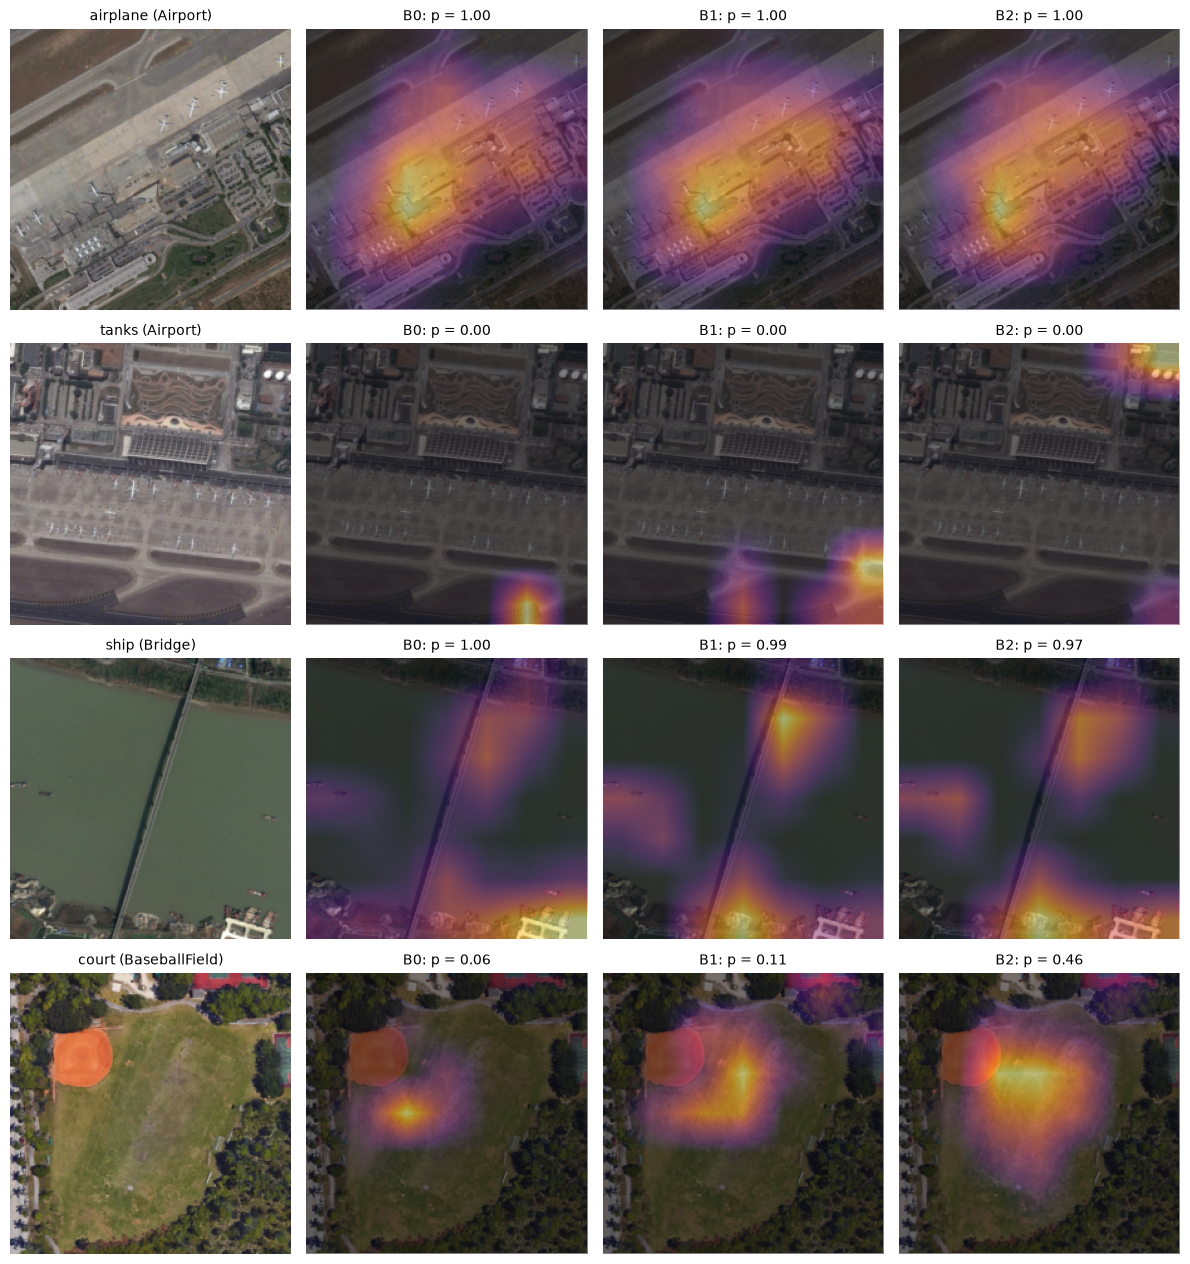

In [22]:
device = get_device()
cam_models = {}
for m in MODELS:
    model = build_model(m, data, pretrained=False).to(device)
    model.load_state_dict(torch.load(CHECKPOINT_DIR / f"{m}_seed{runs[m][0]['seed']}.pt", map_location=device, weights_only=True))
    cam_models[m] = model.eval()


def grad_cam(model, index, label):
    """Grad-CAM map of one object logit at the last ResNet-50 block, scaled to [0, 1]."""
    store = {}
    hook = model.backbone.layer4.register_forward_hook(lambda module, inputs, output: store.update(features=output))
    x = make_batch(data["images"], np.array([index]), device, augment=False)
    object_logits, _ = model(x)
    hook.remove()
    gradients = torch.autograd.grad(object_logits[0, label], store["features"])[0]
    weights = gradients.mean(dim=(2, 3), keepdim=True)
    cam = torch.relu((weights * store["features"]).sum(1))[0]
    cam = cam / (cam.max() + 1e-8)
    return cam.detach().cpu().numpy(), torch.sigmoid(object_logits[0, label]).item()


CAM_LABELS = ["airplane", "tanks", "ship", "court"]
size = data["images"].shape[1]
fig, axes = plt.subplots(len(CAM_LABELS), len(MODELS) + 1, figsize=(3 * (len(MODELS) + 1), 3.2 * len(CAM_LABELS)))
for row, name in zip(axes, CAM_LABELS):
    label = object_names.index(name)
    index = test[np.where(truth[:, label])[0][0]]
    row[0].imshow(data["images"][index])
    row[0].set_title(f"{name} ({data['scene_names'][data['scenes'][index]]})", fontsize=10)
    for ax, m in zip(row[1:], MODELS):
        cam, prob = grad_cam(cam_models[m], index, label)
        ax.imshow(data["images"][index])
        ax.imshow(cam, cmap="inferno", alpha=0.5, extent=(0, size, size, 0), interpolation="bilinear")
        ax.set_title(f"{m}: p = {prob:.2f}", fontsize=10)
    for ax in row:
        ax.axis("off")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "grad_cam.png", dpi=200)
plt.show()